# Start to End simulations with Pvs from the machine mapped as inputs


In [4]:
import os
import torch
import cheetah 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io
import torch.nn as nn

from pytao import Tao
import pandas as pd
from util_bmad import tc, get_output, print_twiss
from util_bmad import (bdesToKmod, get_pvlist, get_bmad, get_tao,  get_tao_dm, get_live, get_pvlist_rf, evaluate_tao,  
make_cmds, getEtot,  print_twiss, bmag, calc_bmag, view, fudge_L1_cmds, fudge_L2_cmds, fudge_L3_cmds, outkeys, 
showemit, get_output, plot_twiss, use_LI21, use_BC2, use_BEGL3, use_LI28, use_LTUH_M, match_init_cmds, match_final_cmds, 
init_cmds, final_cmds, plot_betas)
from lcls_live.datamaps import get_datamaps
from lcls_live.archiver import lcls_archiver_restore
from lcls_live import data_dir
import torch
import matplotlib.pyplot as plt
from pmd_beamphysics import ParticleGroup
import numpy as np
from scipy.constants import c, m_e, e
from scipy.stats import norm
from pmd_beamphysics import ParticleGroup
import numpy as np
from scipy.constants import c, m_e, e
from scipy.stats import norm
from pmd_beamphysics import ParticleGroup
import torch
from xopt import Xopt
from xopt import Evaluator
from xopt import VOCS
import math
from xopt.generators import get_generator 
from xopt import Xopt
import contextlib
import io
import time
#from get_vcc_image import get_live_distgen_xy_dist, VCC_DEVICE_PV
import pandas as pd
import numpy as np

from pmd_beamphysics import single_particle, ParticleGroup

from impact import Impact
from distgen import Generator
import os
from pmd_beamphysics.plot import density_and_slice_plot, slice_plot
import matplotlib.pyplot as plt

from lcls_live.archiver import lcls_archiver_restore


import time
import pandas as pd

from s2e_utils import *

from pytao import Tao
from pmd_beamphysics import ParticleGroup
import h5py
import os
import h5py
import pmd_beamphysics
import numpy as np
from pmd_beamphysics import ParticleGroup
import meme
from datetime import datetime

 # Global

 ### Top inputs

In [6]:
time_data='2025-10-30T19:14:18-07:00' ## Define the time we want. 

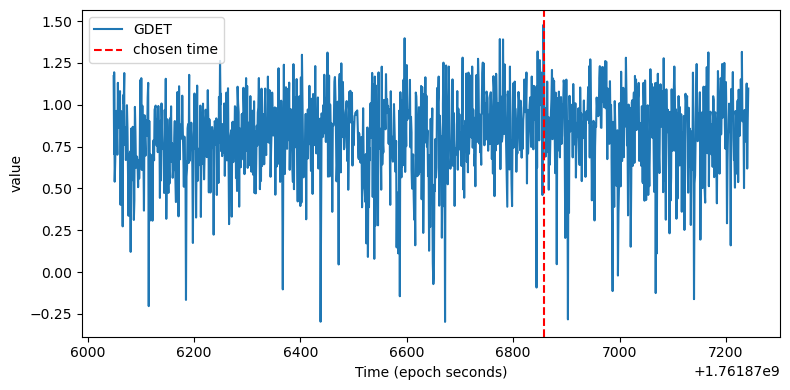

In [8]:
# check the time has good intensity

data = meme.archive.get(
    ["GDET:FEE1:241:ENRC"],
    from_time='2025-10-30 19:00:50',
    to_time='2025-10-30T19:20:43',
    timeout=20.0
)

t = datetime.fromisoformat(time_data)
t_epoch = t.timestamp()

# === Plot ===
plt.figure(figsize=(8,4))

plt.plot(data['secondsPastEpoch'], data['values'], label='GDET')

# vertical line showing chosen timestamp
plt.axvline(t_epoch, color='r', linestyle='--', label='chosen time')

#plt.plot([data['secondsPastEpoch'][0], data['secondsPastEpoch'][-1]], [70, 70])

plt.xlabel("Time (epoch seconds)")
#plt.ylabel("Pulse energy (mJ)")

plt.ylabel('value')
plt.legend()

plt.tight_layout()
plt.show()

# Impact

In [9]:
## Define the lattice

os.environ["LCLS_LATTICE"] ='/sdf/group/ad/beamphysics/lcls-lattice'  #point to the lcls repo here. If you clond your own repo you can pooint to this


## partions to run the impact and genesis simulations. 

partion= 'partition milano'
account= 'ad:default' #'ad:beamphysics'

infile = os.path.expandvars('$LCLS_LATTICE/impact/models/cu_inj/v0/ImpactT.in')
IFILE = os.path.expandvars(infile)



## Set up impact

I = Impact(IFILE, workdir=os.path.expandvars('$SCRATCH'))
I.workdir=os.path.expandvars('$SCRATCH')
## Switches for MPI
I.numprocs = 60
I.stop = 16.5
I.mpi_run

command_mpi=I.command_mpi
settings = {    
 'mpi_run': 'salloc --' + partion +' --account '+ account + ' -N 1 -n {nproc} mpirun -n {nproc} {command_mpi}'
}
for k, v in settings.items():
    I[k] = v
    
I.workdir = os.path.expandvars('$SCRATCH')

#### First lets look at the pv list from Chris Mayes Example And then grab the PVs from lcls live

In [11]:
CSV =  f'pv_mapping/cu_inj_impact.csv' 

DF = pd.read_csv(CSV)#.dropna()

PVLIST = list(DF['device_pv_name'].dropna()) 

USE_VCC=False

VCC_DEVICE = 'CAMR:IN20:186' # LCLS   

if USE_VCC:
    PVLIST = PVLIST + list(VCC_DEVICE_PV[VCC_DEVICE].values())
else:
    print('USE VCC set to False. VCC is not working right now.')
#DF.set_index('device_pv_name', inplace=True)

DF = DF.set_index('device_pv_name')
DF

USE VCC set to False. VCC is not working right now.


,Variable,bmad_name,device_min,device_max,scan_min,scan_max,pv_unit,impact_name,impact_factor,impact_description,impact_unit
device_pv_name,,,,,,,,,,,
SOLN:IN20:121:BACT,Solenoid,SOL1,0.000,0.550,0.350,0.500,kG*m,SOL1:solenoid_field_scale,5.142724e-01,peak field,T
QUAD:IN20:121:BACT,Corrector quad,CQ01,-0.015,0.015,-0.015,0.015,kG,CQ01:b1_gradient,-4.761905e-01,Corrector quad gradient,T/m
QUAD:IN20:122:BACT,Skew quad,SQ01,-0.015,0.015,-0.015,0.015,kG,SQ01:b1_gradient,-4.761905e-01,Skew quad gradient,T/m
ACCL:IN20:300:L0A_PDES,L0A phase,L0A,-20.000,0.000,-20.000,0.000,deg,L0A_phase:dtheta0_deg,1.000000e+00,Phase relative to on-crest,deg
ACCL:IN20:400:L0B_PDES,L0B phase,L0B,-20.000,0.000,-20.000,0.000,deg,L0B_phase:dtheta0_deg,1.000000e+00,Phase relative to on-crest,deg
ACCL:IN20:300:L0A_ADES,L0B voltage,L0A,0.000,110.000,50.000,66.000,MV,L0A_scale:voltage,1.000000e+06,Voltage,V
ACCL:IN20:400:L0B_ADES,L0B voltage,L0B,0.000,110.000,70.000,70.000,MV,L0B_scale:voltage,1.000000e+06,Voltage,V
QUAD:IN20:361:BACT,QA01,QA01,-20.000,20.000,-3.500,-2.750,kG,QA01:b1_gradient,-9.259259e-01,10.8 cm quad,T/m
QUAD:IN20:371:BACT,QA02,QA02,-20.000,20.000,2.500,2.900,kG,QA02:b1_gradient,-9.259259e-01,10.8 cm quad,T/m


In [12]:
## Grab the Pv data - this can be slow and need 2 attemps we add a second attmempt so the whole notebook can be ran and left

try:
    pvdata = lcls_archiver_restore(PVLIST, time_data)
except Exception as e:
    print(f"Archiver request failed: {e}. Retrying in 2 seconds...")
    time.sleep(2)
    pvdata = lcls_archiver_restore(PVLIST, time_data)


Requesting: http://lcls-archapp.slac.stanford.edu/retrieval/data/getDataAtTime?at=2025-10-30T19:14:18-07:00&includeProxies=true
Archiver request failed: Archiver request failed. Response was: 502 - Proxy Error. Retrying in 2 seconds...
Requesting: http://lcls-archapp.slac.stanford.edu/retrieval/data/getDataAtTime?at=2025-10-30T19:14:18-07:00&includeProxies=true


# Distgen

### Generate particles at gun

In [13]:
%%time

#Generator may require the distgen file to specify species, the example provided doesn't do this so this is a work around. 
# It may be eassier just to manally edit disten.yaml to incldue this. 

GFILE_new_path='./distgen.yaml'
ImageFile_new_path='./laser_image.txt'

VCC_image=False

if VCC_image==True:

    ## Here is an example when using a VCC image
    ## This needs more work - still to implement removing noise and centering. 

    GFILE = os.path.expandvars('$LCLS_LATTICE/distgen/models/cu_inj/vcc_image/distgen.yaml')

    ImageFile=os.path.expandvars('./Cathode_CAM/ProfMon-CAMR_IN20_186-2025-10-28-115407.mat')


    os.system(f' cp {GFILE} {GFILE_new_path}')


    vcc_mat_to_txt(
        mat_file=ImageFile,
        output_txt=ImageFile_new_path,
        normalize="sum",
        subtract_bg=True,
        crop=True
    )
    with open(GFILE_new_path, 'a') as f:
        f.write('species: electron\n')
    G = Generator(GFILE_new_path)
    G['n_particle'] = 100_000

else:


   ## If we don't want to provide the VCC image we can instead define the laser on the cathod interms of simga_xy
    
    GFILE = os.path.expandvars('$LCLS_LATTICE/distgen/models/cu_inj/v0/distgen.yaml')
    os.system(f' cp {GFILE} {GFILE_new_path}')

    # --- Fix distgen random syntax for distgen>=3 ---
    with open(GFILE_new_path, "r") as f:
        lines = f.readlines()

    with open(GFILE_new_path, "w") as f:
        for line in lines:
            if "random_type" in line:
                value = line.split(":")[1].strip()
                f.write("random:\n")
                f.write(f"  type: {value}\n")
            else:
                f.write(line)
    ## get the simgas from pvs
    
    pvlist_cam = ['CAMR:IN20:186:XRMS', 'CAMR:IN20:186:YRMS']
    pvdata_cam = lcls_archiver_restore(pvlist_cam, time_data)
 
    sigma_x = pvdata_cam['CAMR:IN20:186:XRMS']
    sigma_y = pvdata_cam['CAMR:IN20:186:YRMS']

    sigma_xy = np.sqrt(sigma_x * sigma_y)


    with open(GFILE_new_path, 'a') as f:
        f.write('species: electron\n')
    G = Generator(GFILE_new_path)
    G['n_particle'] = 10_000

    G['r_dist:sigma_xy:value'] =sigma_xy/1e3
    G['t_dist:length:value'] =4 * 1.65   

G['total_charge']=pvdata['BPMS:IN20:221:TMIT']*DF.loc['BPMS:IN20:221:TMIT', 'impact_factor']

G.run()
P0 = G.particles
P0_store=G.particles ## we will need to do some single particle analysis so lets make sure we can get these back

# Set initial particles
I.initial_particles = P0

Requesting: http://lcls-archapp.slac.stanford.edu/retrieval/data/getDataAtTime?at=2025-10-30T19:14:18-07:00&includeProxies=true
CPU times: user 134 ms, sys: 33.8 ms, total: 168 ms
Wall time: 11.4 s


#### Pass the Pvs into impact

In [15]:
I.configure()

In [16]:

### We can change the PV we chose to include or keep at design

selected_pvs = [
    "SOL1:solenoid_field_scale",
    "CQ01:b1_gradient",
    "SQ01:b1_gradient",
    "QA01:b1_gradient",   ### the quads are after YAG03 so these don't change be before the hand off
    "QA02:b1_gradient",
    "QE01:b1_gradient",
    "QE02:b1_gradient",
    "QE03:b1_gradient",
    "QE04:b1_gradient",
]

USE_SELECTED_PVS = True

rows = []
missing_impact_names = []
update_errors = []



for pv_name, pv_value in pvdata.items():

    # Skip PVs not in mapping
    if pv_name not in DF.index:
        continue

    impact_name   = DF.loc[pv_name, 'impact_name']
    impact_factor = DF.loc[pv_name, 'impact_factor']

    # ---- FIX: filter on impact_name ----
    if USE_SELECTED_PVS and impact_name not in selected_pvs:
        continue

    machine_value = pv_value * impact_factor

    try:
        design_value = I[impact_name]

        diff = machine_value - design_value
        rel_diff = diff / design_value if design_value != 0 else None

        rows.append({
            "pv_name": pv_name,
            "impact_name": impact_name,
            "design_value": design_value,
            "machine_value": machine_value,
            "difference": diff,
            "relative_difference": rel_diff
        })

        I[impact_name] = machine_value

    except KeyError:
        missing_impact_names.append(impact_name)

    except Exception as e:
        update_errors.append((impact_name, str(e)))



comparison_df = pd.DataFrame(rows)

In [18]:
comparison_df  ### Note if design value is simply old value so if you run the box above twice this wont be accurate

,pv_name,impact_name,design_value,machine_value,difference,relative_difference
0,SOLN:IN20:121:BACT,SOL1:solenoid_field_scale,0.2457,0.248356,0.002656,0.010812
1,QUAD:IN20:121:BACT,CQ01:b1_gradient,0.0000,-0.006429,-0.006429,NaN
2,QUAD:IN20:122:BACT,SQ01:b1_gradient,0.0000,-0.001929,-0.001929,NaN
3,QUAD:IN20:361:BACT,QA01:b1_gradient,1.8524,3.367138,1.514738,0.817717
4,QUAD:IN20:371:BACT,QA02:b1_gradient,-1.8524,-2.588766,-0.736366,0.397520
5,QUAD:IN20:425:BACT,QE01:b1_gradient,0.1872,1.413279,1.226079,6.549565
6,QUAD:IN20:441:BACT,QE02:b1_gradient,0.1661,0.359426,0.193326,1.163911
7,QUAD:IN20:511:BACT,QE03:b1_gradient,-2.6409,-2.747610,-0.106710,0.040407
8,QUAD:IN20:525:BACT,QE04:b1_gradient,2.9800,2.353629,-0.626371,-0.210191


## Autophase L0A and L0B

In [19]:
## How long are our elements

L0A_elements = ['L0A_entrance', 'L0A_body_1', 'L0A_exit']

L0A_length = sum(
    elem['L']
    for elem in I.lattice
    if elem.get('name') in L0A_elements
)

print("Total L0A length (m):", L0A_length)


L0B_elements = ['L0B_entrance', 'L0B_body_1', 'L0B_exit']

L0B_length = sum(
    elem['L']
    for elem in I.lattice
    if elem.get('name') in L0B_elements
)

print("Total L0B length (m):", L0B_length)

Total L0A length (m): 3.042856
Total L0B length (m): 3.042856


In [23]:
Gun_energy_pv=['BEND:IN20:231:EDES']       # Energy measurement after gun

max_attempts = 5

for attempt in range(max_attempts):
    try:
        pvdata_new = lcls_archiver_restore(Gun_energy_pv, time_data)
        print("Success")
        break
    except Exception as e:
        print(f"Attempt {attempt+1} failed: {e}")
        time.sleep(2)
else:
    raise RuntimeError("Failed to retrieve PV data after multiple attempts")

Requesting: http://lcls-archapp.slac.stanford.edu/retrieval/data/getDataAtTime?at=2025-10-30T19:14:18-07:00&includeProxies=true
Success


In [27]:
# ---- L0A ----

energy_L0A_MeV=pvdata['ACCL:IN20:300:L0A_ADES']#*np.cos(np.deg2rad(pvdata['ACCL:IN20:300:L0A_PDES']))


# ---- L0B ----

energy_L0B_MeV=pvdata['ACCL:IN20:400:L0B_ADES']#*np.cos(np.deg2rad(pvdata['ACCL:IN20:400:L0B_PDES']))

E_gun_GeV = pvdata_new["BEND:IN20:231:EDES"]
E_gun_MeV = E_gun_GeV * 1000

print("Gun energy (GeV):", E_gun_GeV)
print("Gun energy (MeV):", E_gun_MeV)
print("L0A energy gain (MeV):", energy_L0A_MeV)
print("L0B energy gain (MeV):", energy_L0B_MeV)
print('Gun energy+ L0A_energy:', energy_L0A_MeV +  E_gun_MeV)
print("Gun energy + L0B gain (MeV):", energy_L0A_MeV + energy_L0B_MeV)
print("Total L0A + L0B gain (MeV) plus GUN energy:", energy_L0A_MeV + energy_L0B_MeV + E_gun_MeV)

target_L0A = energy_L0A_MeV + E_gun_MeV

Gun energy (GeV): 0.006
Gun energy (MeV): 6.0
L0A energy gain (MeV): 58.5
L0B energy gain (MeV): 64.87839911656194
Gun energy+ L0A_energy: 64.5
Gun energy + L0B gain (MeV): 123.37839911656194
Total L0A + L0B gain (MeV) plus GUN energy: 129.37839911656192


In [28]:
I.add_group(
    "L0A",
    ele_names=["L0A_entrance", "L0A_body_1", "L0A_body_2", "L0A_exit"],
    var_name="theta0_deg",
    attributes="theta0_deg",
)

I.add_group(
    "L0A_scale",
    ele_names=["L0A_entrance", "L0A_body_1", "L0A_body_2", "L0A_exit"],
    var_name="rf_field_scale",
    factors=[0.86571945106805, 1, 1, 0.86571945106805],  # sin(k*d) with d = 3.5e-2 m
    absolute=True,
)

I["L0A"]#["theta0_deg"] 

I["L0A_scale"]["rf_field_scale"]

#I["L0A_body_1"]["theta0_deg"]
I["L0A_entrance"]["rf_field_scale"], I["L0A_body_1"]["rf_field_scale"], I["L0A_body_2"]["rf_field_scale"], I["L0A_exit"]["rf_field_scale"]

(0.0, 0.0, 0.0, 0.0)

In [29]:
import copy

## We should check we get the energy from the gun that we expect.  

P0 = single_particle(pz=1e-15, z=1e-15)  ## single particle
I2 = copy.deepcopy(I) #Copy Impact object for initial energy determination
I2.numprocs=1 #Don't run single particle on many cores
t = I2.track(P0,s=0.9) #Get initial energy
E = t['mean_energy'] #Initial energy

print(E)

E_gun_MeV=E/1e6

6000005.136009727


In [30]:
from impact.autophase import autophase_and_scale

## Now we use autophase 

I.initial_particles = P0

target_L0A = energy_L0A_MeV + E_gun_MeV

I.numprocs = 1

I.add_group(
    "L0A",
    ele_names=["L0A_entrance", "L0A_body_1", "L0A_body_2", "L0A_exit"],
    var_name="theta0_deg",
    attributes="theta0_deg",
)

I.add_group(
    "L0A_scale",
    ele_names=["L0A_entrance", "L0A_body_1", "L0A_body_2", "L0A_exit"],
    var_name="rf_field_scale",
    factors=[0.86571945106805, 1, 1, 0.86571945106805],  # sin(k*d) with d = 3.5e-2 m
    absolute=True,
)

phase=I["L0A"]["theta0_deg"] 

print(phase)

res_L0A = autophase_and_scale(
    I,
    phase_ele_name="L0A",
    scale_ele_name="L0A_scale",
    target=target_L0A*1e6,
    scale_range=(10e6, 100e6),
    initial_particles=P0,
    verbose=True,
)


I["L0A"]["theta0_deg"]=I["L0A"]["theta0_deg"]#+PA_L0A

0.0
Copied initial Impact object. 
Phasing L0A by changing theta0_deg
Scaling L0A_scale by changing rf_field_scale
Bounds: 1.485, 4.527856 m
Tracking initial particles to s = 1.485
Initial particle:  1.4859634055906212 6000005.136009727
Disabling GUN
Disabling SOL1
Disabling L0B_entrance
Disabling L0B_body_1
Disabling L0B_body_2
Disabling L0B_exit
Default brent2 algorithm
Phase: 180, Scale: 10000000.0, 14.168843949072913 MeV
Phase: 180, Scale: 10000000.0, 14.168843949072913 MeV
Phase: 42.49224000000004, Scale: 10000000.0, 19.847258716475075 MeV
Phase: 264.9844890561601, Scale: 10000000.0, 8.746719536217 MeV
Phase: 42.49223440298533, Scale: 10000000.0, 19.84726011584479 MeV
Phase: 264.9844709438398, Scale: 10000000.0, 8.746716736506182 MeV
Phase: 222.4922598928622, Scale: 10000000.0, 10.372730552842922 MeV
Phase: 127.47670402554945, Scale: 10000000.0, 8.236771196433342 MeV
Phase: 333.73836413925164, Scale: 10000000.0, 23.449612789696577 MeV
Phase: 291.2461346846752, Scale: 10000000.0, 1

In [31]:

## and the second cavity

#energy_L0B_MeV=70  ## changing this to see what happens

target_L0B=energy_L0A_MeV + energy_L0B_MeV + E_gun_MeV

I.add_group(
    "L0B",
    ele_names=["L0B_entrance", "L0B_body_1", "L0B_body_2", "L0B_exit"],
    var_name="theta0_deg",
    attributes="theta0_deg",
)

I.add_group(
    "L0B_scale",
    ele_names=["L0B_entrance", "L0B_body_1", "L0B_body_2", "L0B_exit"],
    var_name="rf_field_scale",
    factors=[0.86571945106805, 1, 1, 0.86571945106805],
    absolute=True,
)

print(I["L0A"]["theta0_deg"])

phase=pvdata['ACCL:IN20:400:L0B_PDES'] #I["L0B"]["theta0_deg"]   ### this maybe should take the phase from L0A ... need to check
 
res_L0B = autophase_and_scale(
    I,
    phase_ele_name="L0B",
    scale_ele_name="L0B_scale",
    target=target_L0B* 1e6,
    scale_range=(10e6, 100e6),
    initial_particles=P0,
    verbose=True,
)

print(I["L0B"]["theta0_deg"], 'peak phase')

I["L0B"]["theta0_deg"]=I["L0B"]["theta0_deg"]+pvdata['ACCL:IN20:400:L0B_PDES'] 

print(I["L0B"]["theta0_deg"])

3.0029318934501794
Copied initial Impact object. 
Phasing L0B by changing theta0_deg
Scaling L0B_scale by changing rf_field_scale
Bounds: 5.328756, 8.371612 m
Tracking initial particles to s = 5.328756
Initial particle:  5.329344550330999 64499920.47456119
Disabling GUN
Disabling SOL1
Disabling L0A_entrance
Disabling L0A_body_1
Disabling L0A_body_2
Disabling L0A_exit
Default brent2 algorithm
Phase: 180, Scale: 10000000.0, 45.20779336946081 MeV
Phase: 180, Scale: 10000000.0, 45.20779336946081 MeV
Phase: 42.49224000000004, Scale: 10000000.0, 79.17748658263211 MeV
Phase: 264.9844890561601, Scale: 10000000.0, 62.15644873696489 MeV
Phase: 42.49223440298533, Scale: 10000000.0, 79.1774878078055 MeV
Phase: 264.9844709438398, Scale: 10000000.0, 62.15644268335201 MeV
Phase: 222.49225015787715, Scale: 10000000.0, 49.834695408585816 MeV
Phase: 127.47670402554945, Scale: 10000000.0, 53.28140793542673 MeV
Phase: 333.73836042081825, Scale: 10000000.0, 81.50525989002317 MeV
Phase: 291.2461286681237, S

### Ready to run impact

In [32]:
## put the particles and processes back
I.numprocs = 60
I.initial_particles = P0_store


### Finally we can run impact
I.stop = 16.5
I.verbose=True
I.run()


Running Impact-T in /sdf/scratch/users/j/jmorgan/tmpgnjabszl
salloc --partition milano --account ad:default -N 1 -n 60 mpirun -n 60 /sdf/home/j/jmorgan/conda/envs/lume/bin/ImpactTexe-mpi
writing 10000 particles to /sdf/scratch/users/j/jmorgan/tmpgnjabszl/partcl.data
Cathode start with cathode_kinetic_energy_ref = 1.0 eV
Cathode start: Replaced Np with 10000 according to initial particles
Cathode start: Replaced Bkenergy with 1.0 according to initial particles
Cathode start: Replaced Temission with 6.309254413937858e-12 according to initial particles
Cathode start: Replaced Tini with -3.179927056427367e-12 according to initial particles
Setting total charge to 2.509957507568546e-10 C


salloc: Pending job allocation 25617390
salloc: job 25617390 queued and waiting for resources
salloc: job 25617390 has been allocated resources
salloc: Granted job allocation 25617390
salloc: Waiting for resource configuration
salloc: Nodes sdfmilan225 are ready for job


 !-----------------------------------------------------------
 ! IMPACT-T Parallel Beam Dynamics Tracking Code: V3.0
 ! Copyright of The Regents of the University of California
 !-----------------------------------------------------------
 nblem:           28          28
 check randomness:           19  0.17171624189574408     
 check randomness:           20  0.40590969210418182     
 pass setting up lattice...
 check randomness:            0  0.14406572443031795     
 check randomness:           18  0.27617778141938842     
 check randomness:           29   5.2432615130403315E-003
 check randomness:            3  0.63240637971280000     
 check randomness:            2  0.19026240573326136     
 check randomness:           27  0.45723812476623060     
 time:    445.88048139400001, elapsed: 579.57302927970892156318511870, elapsed: 579.4807951450348670522

salloc: Relinquishing job allocation 25617390


Finished.
Loaded fort 18 : Time and energy
Loaded fort 24 : RMS X information
Loaded fort 25 : RMS Y information
Loaded fort 26 : RMS Z information
Loaded fort 27 : Max amplitude information
Loaded fort 28 : Load balance and loss diagnostics
Loaded fort 29 : Cube root of third moments of the beam distribution
Loaded fort 30 : Fourth root of the fourth moments of the beam distribution
Loaded fort 32 : Covariance matrix of the beam distribution
Loaded fort 60 : Slice information of the initial distribution
Loaded fort 70 : Slice information of the final distribution
Loading particles
Loaded fort 40 : initial particle distribution at t = 0
Loaded fort 50 : final particle distribution projected to the centroid location of the bunch
Loaded write beam particles YAG02 fort.102
Loaded write beam particles YAG03 fort.103
Loaded write beam particles OTR1 fort.105
Loaded write beam particles OTR2 fort.107
Converting z to t according to cathode_kinetic_energy_ref = 1.0 eV
Converted initial_particl

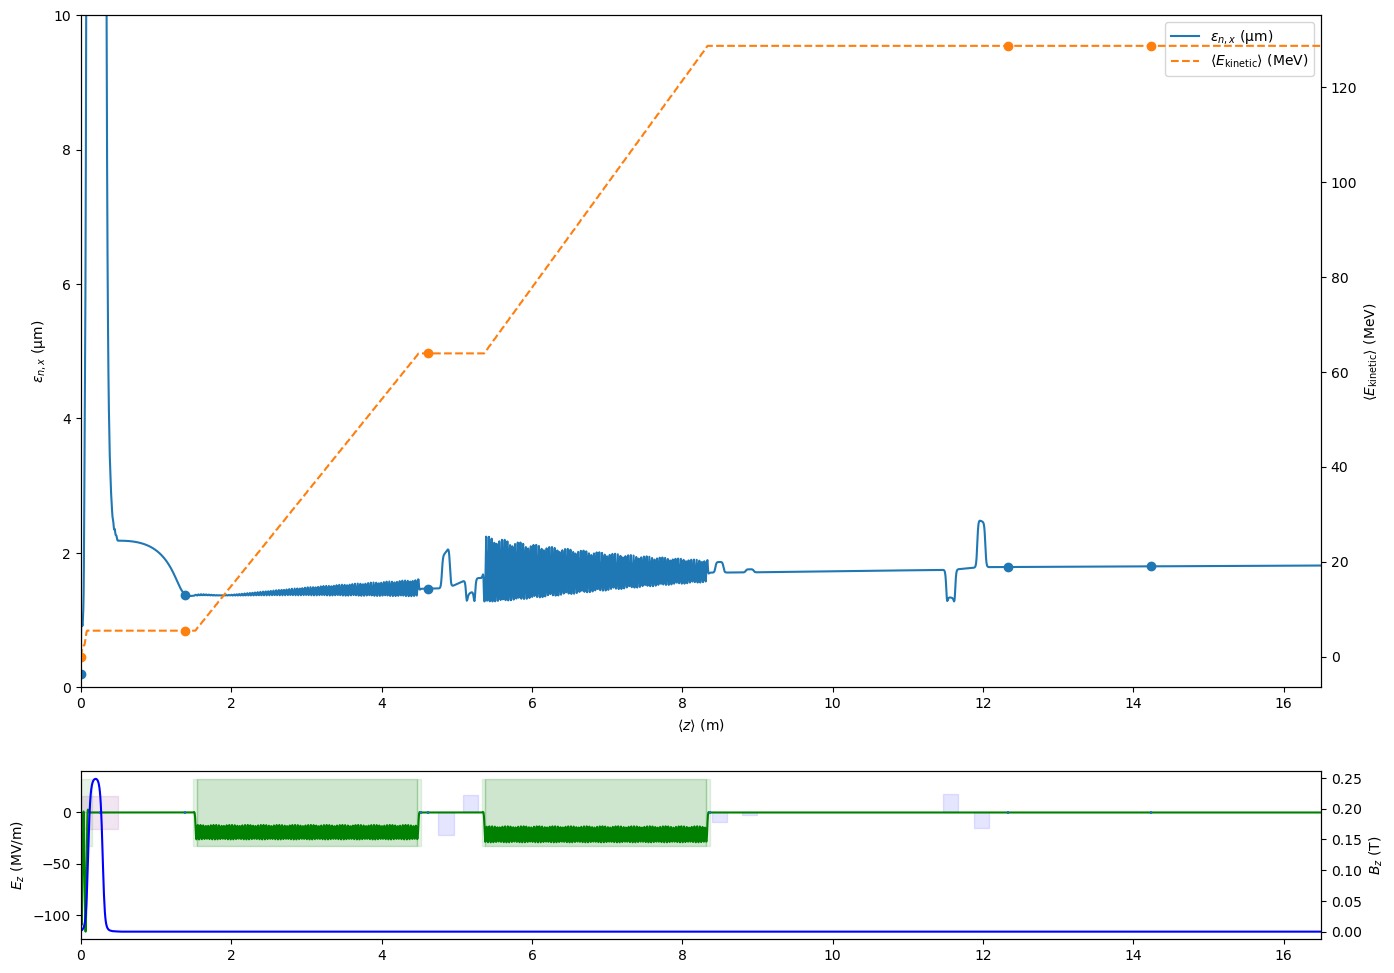

In [33]:
I.plot('norm_emit_x', y2='mean_kinetic_energy', ylim=(0, 10e-6), figsize=(16,12), include_labels=False)

#### Save the particles - you can restart by reading in the particles if you don't want to run impact again

In [34]:
# Write the particles to a file 
folder_path='./store_particles/'
if not os.path.exists(folder_path):
    os.makedirs(folder_path)
PFILE0 = folder_path + 'impact_inj_output.h5'

P_impact=I.particles['YAG03']

P_impact.drift_to_z(I["YAG03"]["s"]) 
print(I["YAG03"]["s"])
P_impact.write(PFILE0)   ## Currently there are issues if handing off at OTR2 so chose YAG03 -impact can't do laser heater anyway

4.614538605


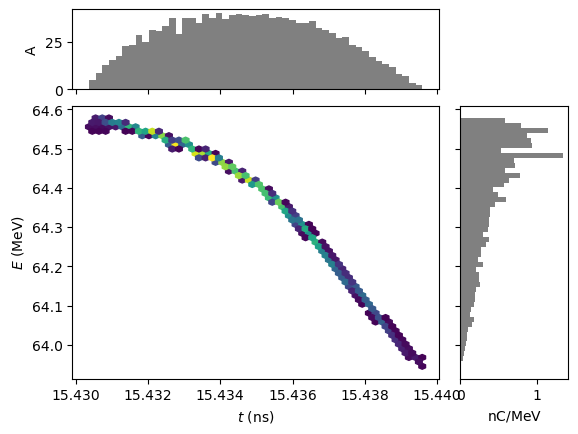

In [35]:
P_impact.plot('t', 'energy')

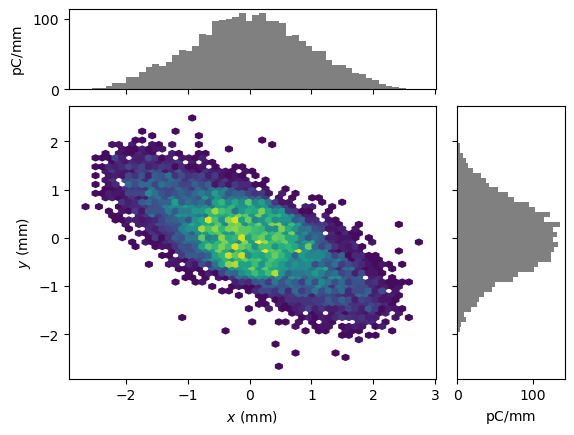

In [36]:
## look at what impact has at OTR2- this will not match bmad unless you don't model the laser heater chicane. 

P_otr2=I.particles['OTR2']
P_otr2.drift_to_z(I["OTR2"]["s"])
P_otr2.plot('x', 'y')

# BMAD

#### If impact has already run and saved the particle file we can restart from here

In [37]:
folder_path='./store_particles/'  ## Re define this so we can restart here if needed

TRACK_START ="YAG03" #'OTR2'#"YAG03" #here to start particle tracking with bmad

PFILE0 = folder_path + '/impact_inj_output.h5'
#PFILE0 = folder_path + '/impact_inj_output_design.h5'
# File to write

PFILE = f'bmad_particles_at_{TRACK_START}.h5' 
PFILE=folder_path+PFILE
# Twiss Match parameters (optional) 
twiss_match = False 

P = ParticleGroup(PFILE0)

In [41]:
from pathlib import Path
import json

pv_file = Path("pvdata_with_correctors.json")

if pv_file.exists():
    print("Loading PV data from file...")
    with open(pv_file, "r") as f:
        pvdata_all = json.load(f)
    print("PV data loaded.")

else:
    print("PV file not found. Pulling from archiver...")

    ALL_DATAMAPS = get_datamaps('cu_hxr')
    PV_LIST = get_pvlist(ALL_DATAMAPS)

    pv_chunks = np.array_split(PV_LIST, 20)
    pvdata_all = {}

    max_retries = 5
    wait_seconds = 2

    for i, chunk in enumerate(pv_chunks):
        print(f"Restoring chunk {i+1}/{len(pv_chunks)} with {len(chunk)} PVs...")

        attempt = 0
        while attempt < max_retries:
            try:
                chunk_data = lcls_archiver_restore(list(chunk), time_data)
                pvdata_all.update(chunk_data)
                print(f"Chunk {i+1} successful.")
                break

            except Exception as e:
                attempt += 1
                print(f"Error on chunk {i+1}, attempt {attempt}/{max_retries}: {e}")

                if attempt < max_retries:
                    print(f"Waiting {wait_seconds} seconds before retrying...")
                    time.sleep(wait_seconds)
                else:
                    print(f"Chunk {i+1} failed after {max_retries} attempts.")
                    raise

    print("Done pulling PVs.")

    # Save after successful pull
    with open(pv_file, "w") as f:
        json.dump(pvdata_all, f)

    print("PV data saved.")

Loading PV data from file...
PV data loaded.


### Here we split bmad up to OTR2 and then to the start of the first undulator
### This is so we can match the beam to measurement at OTR2 if we want

In [47]:
def run_lcls_segment_tracking_YAG03_OTR2(time_data, track_start_element_name, track_end_element_name, pvdata,  P=None, PFILE=None, Twiss_inputs=None, inital_energy=None,  pvdata_L0B=None):

    from pytao import Tao
   
    BEAMPATH = "cu_hxr/cu_hxr.lat.bmad"
    cu_hxr_file_path = f'/sdf/home/j/jmorgan/beamphysics/lcls-lattice/bmad/models/{BEAMPATH}'

    cu_hxr_file_path = f'/sdf/home/j/jmorgan/beamphysics/lcls-lattice/bmad/models/{BEAMPATH}'
    lcls_lattice_dir = '/sdf/home/j/jmorgan/beamphysics/lcls-lattice' #os.environ["LCLS_LATTICE"] 

    BEAMPATH = 'cu_hxr'
    OPTIONS = f'-slice {track_start_element_name}:{track_end_element_name} -noplot '

    INIT = f'-init /sdf/home/j/jmorgan/lclsrepo_dontsharethese/lcls-lattice/bmad/models/{BEAMPATH}/tao.init {OPTIONS}'

    tao = Tao(INIT)


    bmad_output_design = get_output(tao)


    floorplan=pd.read_csv(io.StringIO('\n'.join(tao.show('lat -all -floor_coords -tracking_elements')[3:-5])), sep="[\s\n]+",engine='python',
            names=['Index','ElementName','ElementType','s','ds','X','Y','Z','Theta','Phi','Psi'])
    floorplan.drop(0,inplace=True)


    floorplan_elements = set(floorplan['ElementName'])

    ALL_DATAMAPS = get_datamaps('cu_hxr')

    del ALL_DATAMAPS['bpms']
    del ALL_DATAMAPS['correctors']

    PV_LIST = get_pvlist(ALL_DATAMAPS)

    tao_cmds = get_tao(pvdata, ALL_DATAMAPS)  
    nonelements =0
    for cmd in tao_cmds:
        try:
            tao.cmd(cmd)
                #print('command success -->', cmd)
        except RuntimeError:
                nonelements=nonelements+1

    tao.cmd('place floor sigmaxy')
    tao.cmd(f'set beam_init track_start = {track_start_element_name}')
    tao.cmd(f'set beam_init track_end = {track_end_element_name}')


    ### Change the intial energy if the particles are different
    
    if inital_energy:  ## perhaps we should pass this in from autophaseing
        tao.cmd(f'set ele 0 e_tot = {inital_energy}')  
    else:
        inital_energy=np.mean(P.energy)
        tao.cmd(f'set ele 0 e_tot = {inital_energy}')

#    run_fudge_optimization(tao)

    voltage= pvdata_L0B['ACCL:IN20:400:L0B_ADES']*1e6
    phase= pvdata_L0B['ACCL:IN20:400:L0B_PDES']/ 360

    tao.cmd(f"set ele L0B autoscale_amplitude = F")
    tao.cmd(f"set ele L0B autoscale_phase = F")

    phase_0=tao.evaluate('ele::L0B[phi0]')[0]
    
    tao.cmd(f"set ele L0B voltage = {voltage}")  ##Compent these out if you want to use design
    tao.cmd(f"set ele L0B phi0 = {phase}")    

    ## Quads are scaled to energy so lets reaply 
    pvdata_quads = {k: v for k, v in pvdata_all.items() if "QUAD" in k}
    tao_cmds = get_tao(pvdata, ALL_DATAMAPS)  
    nonelements =0
    for cmd in tao_cmds:
        try:
            tao.cmd(cmd)
                #print('command success -->', cmd)
        except RuntimeError:
                nonelements=nonelements+1
    
    
    if Twiss_inputs:
        twiss=Twiss_inputs
        beta_x=twiss['beta_x']
        beta_y=twiss['beta_y']
        alpha_x=twiss['alpha_x']
        alpha_y=twiss['alpha_y']
        #charge=twiss['charge']
    
        tao.cmd(f'set ele 0 beta_a = {beta_x}')
        tao.cmd(f'set ele 0 beta_b = {beta_y}') 
        tao.cmd(f'set ele 0 alpha_a = {alpha_x}')
        tao.cmd(f'set ele 0 alpha_b = {alpha_y}')
        
    particles=True ## hard codeing this but should have the option to change

    if particles:
        print('here')
        t_ref = tao.evaluate(f'ele::{TRACK_START}[ref_time]')[0]
        # write particle file exactly as it came from Impact
        P.write(PFILE)

        with h5py.File(PFILE, "r+") as f:
            # get particle path
            pp = pmd_beamphysics.readers.particle_paths(f)[0] + "/electron"

            # read times
            t = f[pp]['time'][()]

            # compute bunch center
            tmean = np.mean(t)

            #weights = f[pp]['weight'][()]
            #tref = np.average(t, weights=weights)
            
            #      subtract mean
           # f[pp]['time'][...] += t_ref - tmean
            f[pp]['time'][...] += - tmean

            # add timeOffset dataset
            #f[pp]['timeOffset'] = np.full(len(t), tmean)
            f[pp]['timeOffset'] = np.full(len(t), tmean)


             # copy attributes so units match
            for k,v in f[pp]['time'].attrs.items():
                f[pp]['timeOffset'].attrs[k] = v
        
        tao.cmd('set global plot_on = F')
        tao.cmd('set global lattice_calc_on = F')
        tao.cmd(f'set beam_init position_file = {PFILE}')
        tao.cmd(f'set beam_init track_start = { track_start_element_name}')
        tao.cmd(f'set beam_init track_end = { track_end_element_name}')
        tao.cmd(f'set beam_init bunch_charge = {P.charge}')
        tao.cmd(f'set beam_init n_particle = {len(P)}')
        
        tao.cmd('set global lattice_calc_on = T')

    tao.cmd('set global lattice_calc_on = F')


    tao.cmd(f'set beam_init track_start = {track_start_element_name}')
    tao.cmd(f'set beam_init track_end = {track_end_element_name}')
    
    if Twiss_inputs:
        twiss=Twiss_inputs
        beta_x=twiss['beta_x']
        beta_y=twiss['beta_y']
        alpha_x=twiss['alpha_x']
        alpha_y=twiss['alpha_y']
        #charge=twiss['charge']
    
        tao.cmd(f'set ele 0 beta_a = {beta_x}')
        tao.cmd(f'set ele 0 beta_b = {beta_y}') 
        tao.cmd(f'set ele 0 alpha_a = {alpha_x}')
        tao.cmd(f'set ele 0 alpha_b = {alpha_y}')


    tao.cmd('set global lattice_calc_on = T')


    tao.cmd('set global track_type = beam')
    
    bmad_output = get_output(tao)
    
    
    return bmad_output_design, bmad_output, tao, floorplan

In [43]:
TRACK_START='YAG03'
TRACK_END= 'OTR2' #'OTR1' #'UMAHXH14#1'  #'OTR2' # 'BEGBC2' # 'BC2CEND' # 'BEGBC1' #'BC1CEND' #'UMAHXH14#1' #track all the way to the start of the first undulator

tw = P.twiss('xy')

Twiss_inputs = {
    'beta_x':  tw['beta_x'],
    'beta_y':  tw['beta_y'],
    'alpha_x': tw['alpha_x'],
    'alpha_y': tw['alpha_y']
}

pvdata_no_quads = {k: v for k, v in pvdata_all.items() if "QUAD" not in k}   ### The quads need to be fixed to get the phase space lets just make these design

with contextlib.redirect_stdout(io.StringIO()):
    bmad_output_design, bmad_output, tao, floorplan= run_lcls_segment_tracking_YAG03_OTR2(time_data, TRACK_START, TRACK_END, pvdata_no_quads, P=P, PFILE=PFILE, pvdata_L0B=pvdata) 

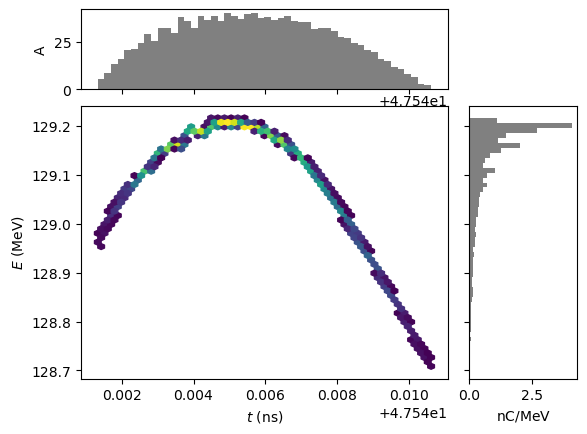

In [46]:
P1 = ParticleGroup(data=tao.bunch_data(TRACK_END))

P1.plot('t', 'energy')

P1.write('Particles_OTR2')

P_OTR2 = ParticleGroup('Particles_OTR2')

In [50]:
twiss_match=True
if twiss_match:
    P_OTR2.twiss_match(beta =  1.7  , alpha =0.03, plane = 'x', inplace = True)
    P_OTR2.twiss_match(beta =  1.9  , alpha =-0.91, plane = 'y', inplace = True)

### Artifically increase the beam energy to match OTR2 measument. Eventually we should need any of this
P_OTR2.gamma=P_OTR2.gamma+((0.135e9)-max(P_OTR2.energy))/P_OTR2.energy*P_OTR2.gamma

In [79]:
def run_lcls_segment_tracking(time_data, track_start_element_name, track_end_element_name, pvdata,  P=None, PFILE=None, Twiss_inputs=None, inital_energy=None,  pvdata_L0B=None, T_ref_1=None, L1_phase=None, L2_phase = None):

    from pytao import Tao

    
    
    BEAMPATH = "cu_hxr/cu_hxr.lat.bmad"
    cu_hxr_file_path = f'/sdf/home/j/jmorgan/beamphysics/lcls-lattice/bmad/models/{BEAMPATH}'

    cu_hxr_file_path = f'/sdf/home/j/jmorgan/beamphysics/lcls-lattice/bmad/models/{BEAMPATH}'
    lcls_lattice_dir = '/sdf/home/j/jmorgan/beamphysics/lcls-lattice' #os.environ["LCLS_LATTICE"] 
    #lcls_cu_segment = (
     #   cheetah.Segment.from_bmad(
     #   str(cu_hxr_file_path),
     #   environment_variables={"LCLS_LATTICE": lcls_lattice_dir},
     #))
 
    #lcls_cu_segment = lcls_cu_segment.flattened()
    #CU_HXR model
    BEAMPATH = 'cu_hxr'
    OPTIONS = f'-slice {track_start_element_name}:{track_end_element_name} -noplot '
    #OPTIONS = f'-slice {track_start_element_name}: -noplot '
    #INIT = f'-init $LCLS_LATTICE/bmad/models/{BEAMPATH}/tao.init {OPTIONS}'
    INIT = f'-init /sdf/home/j/jmorgan/lclsrepo_dontsharethese/lcls-lattice/bmad/models/{BEAMPATH}/tao.init {OPTIONS}'

    tao = Tao(INIT)

    tao.cmd('set ele O_BC1_OFFSET offset = 0.001 * 246.26531311298407')
    tao.cmd('set ele O_BC2_OFFSET offset = 0.001 * 385.26778801902003')

    bmad_output_design = get_output(tao)

    energy_design_BC1=tao.ele_gen_attribs('BX11')['E_TOT']
    energy_design_BC2=tao.ele_gen_attribs('BX21')['E_TOT']


    floorplan=pd.read_csv(io.StringIO('\n'.join(tao.show('lat -all -floor_coords -tracking_elements')[3:-5])), sep="[\s\n]+",engine='python',
            names=['Index','ElementName','ElementType','s','ds','X','Y','Z','Theta','Phi','Psi'])
    floorplan.drop(0,inplace=True)


    floorplan_elements = set(floorplan['ElementName'])

    ALL_DATAMAPS = get_datamaps('cu_hxr')


    del ALL_DATAMAPS['bpms']
    del ALL_DATAMAPS['correctors']
    #del ALL_DATAMAPS['quad']
   # del ALL_DATAMAPS['linac']
    del ALL_DATAMAPS['beginning_WS02']

    if inital_energy:  ## perhaps we should pass this in from autophaseing
        tao.cmd(f'set ele 0 e_tot = {inital_energy}')  
    else:
        inital_energy=np.max(P.energy)
        tao.cmd(f'set ele 0 e_tot = {inital_energy}')


 #   del ALL_DATAMAPS['bpms']
#    del ALL_DATAMAPS['correctors']

    PV_LIST = get_pvlist(ALL_DATAMAPS)

#
    tao_cmds = get_tao(pvdata, ALL_DATAMAPS)  
    nonelements =0
    for cmd in tao_cmds:
        try:
            tao.cmd(cmd)
          #  print('command success -->', cmd)
        except RuntimeError:
            nonelements=nonelements+1

    tao.cmd('place floor sigmaxy')
    tao.cmd(f'set beam_init track_start = {track_start_element_name}')
    tao.cmd(f'set beam_init track_end = {track_end_element_name}')


    if L1_phase:
        tao.cmd(f'set ele K21_1 phase_deg = {L1_phase} ')
    if L2_phase:
        tao.cmd(f'set ele  O_L2  phase_deg = {L2_phase} ')

    run_fudge_optimization(tao)


    pvdata_quads = {k: v for k, v in pvdata.items() if "QUAD" in k}


    ALL_DATAMAPS_QUAD = {'quad': ALL_DATAMAPS['quad']}
    tao_cmds = get_tao(pvdata_quads, ALL_DATAMAPS_QUAD)      
    nonelements =0
    for cmd in tao_cmds:
        try:
            tao.cmd(cmd)
               #print('command success -->', cmd)
        except RuntimeError:
                nonelements=nonelements+1

    
    if Twiss_inputs:
        twiss=Twiss_inputs
        beta_x=twiss['beta_x']
        beta_y=twiss['beta_y']
        alpha_x=twiss['alpha_x']
        alpha_y=twiss['alpha_y']
        #charge=twiss['charge']
    
        tao.cmd(f'set ele 0 beta_a = {beta_x}')
        tao.cmd(f'set ele 0 beta_b = {beta_y}') 
        tao.cmd(f'set ele 0 alpha_a = {alpha_x}')
        tao.cmd(f'set ele 0 alpha_b = {alpha_y}')

       # tao.cmd('set ele 0 x_position = -0.001')


    particles=True ## hard codeing this but should have the option to change



    if particles:
        print('here')
        t_ref = tao.evaluate(f'ele::{TRACK_START}[ref_time]')[0]
        
        P.write(PFILE)

        with h5py.File(PFILE, "r+") as f:
            # get particle path
            pp = pmd_beamphysics.readers.particle_paths(f)[0] + "/electron"

            # read times
            t = f[pp]['time'][()]

            # compute bunch center
            tmean = np.mean(t)

            #weights = f[pp]['weight'][()]
            #tref = np.average(t, weights=weights)
            
            #      subtract mean

            t_ref= tmean #+0.6*(np.max(t)-np.min(t)) 
            f[pp]['time'][...] += - t_ref #- 9.7e-12
            #f[pp]['time'][...] += - tmean-4.7524631086445815e-08

            # add timeOffset dataset
            f[pp]['timeOffset'] = np.full(len(t), tmean)
#            f[pp]['timeOffset'] = np.full(len(t),8)

             # copy attributes so units match
            for k,v in f[pp]['time'].attrs.items():
                f[pp]['timeOffset'].attrs[k] = v
        
        tao.cmd('set global plot_on = F')
        tao.cmd('set global lattice_calc_on = F')
        tao.cmd(f'set beam_init position_file = {PFILE}')
        tao.cmd(f'set beam_init track_start = { track_start_element_name}')
        tao.cmd(f'set beam_init track_end = { track_end_element_name}')
        tao.cmd(f'set beam_init bunch_charge = {P.charge}')
        tao.cmd(f'set beam_init n_particle = {len(P)}')
        
        tao.cmd('set global lattice_calc_on = T')

    tao.cmd('set global lattice_calc_on = F')


    tao.cmd(f'set beam_init track_start = {track_start_element_name}')
    tao.cmd(f'set beam_init track_end = {track_end_element_name}')


#    offset_new, angle_new_BC1 = correct_bc1_offset(tao, energy_design_BC1)

 #   tao.cmd(f'set ele O_BC1_OFFSET offset = {offset_new}')

    
 #   offset_new, angle_new = correct_bc2_offset(tao, energy_design_BC2)
 #   tao.cmd(f'set ele O_BC2_OFFSET offset = {offset_new}')


    
    if Twiss_inputs:
        twiss=Twiss_inputs
        beta_x=twiss['beta_x']
        beta_y=twiss['beta_y']
        alpha_x=twiss['alpha_x']
        alpha_y=twiss['alpha_y']
        #charge=twiss['charge']
    
        tao.cmd(f'set ele 0 beta_a = {beta_x}')
        tao.cmd(f'set ele 0 beta_b = {beta_y}') 
        tao.cmd(f'set ele 0 alpha_a = {alpha_x}')
        tao.cmd(f'set ele 0 alpha_b = {alpha_y}')


    tao.cmd('set global lattice_calc_on = F')

#    tao.cmd("set ele O_BC2_OFFSET OFFSET =  0.4338")


    tao.cmd(f'set ele CE11 x1_limit = {-3.650730380137011*-0.001}')

    tao.cmd(f'set ele CE11 x2_limit = {2.8522161832971817*0.001}')

    
    tao.cmd("set global lattice_calc_on = T")
  #  tao.cmd("show ele BX21")  # check ANGLE ≈ -1.892 deg

    tao.cmd('set global track_type = beam')


    print(tao.evaluate("ele::BX21[angle]"), 'angle')  # confirm angle changed
    print(tao.evaluate("ele::BX21[G]"), 'G')       # confirm G changed



    
    
    bmad_output = get_output(tao)


    return bmad_output_design, bmad_output, tao, floorplan

In [52]:
import numpy as np

#### Leaving as an example but probably shouldnt use


def correct_bc2_offset(tao, energy_design):
    
    knots = [
        (-0.2, 1.10073799),
        (-0.13333333, 0.7338735),
        (-0.06666667, 0.3669512),
        (0, 0),
        (0.06666667, -0.3669512),
        (0.13333333, -0.7338735),
        (0.2, -1.10073799),
        (0.26666667, -1.4675158),
        (0.33333333, -1.8341781),
        (0.4, -2.20069612),
        (0.46666667, -2.56704115),
        (0.53333333, -2.93318456),
        (0.6, -3.29909781)
    ]
    angle_design = tao.ele_gen_attribs('BX21')['ANGLE']  # rad at 5.0 GeV
    

    offsets = np.array([k[0] for k in knots])
    angles_deg = np.array([k[1] for k in knots])

    energy_actual = tao.ele_gen_attribs('BX21')['E_TOT']
    #angle_correct = angle_design * (energy_design / energy_actual)
    BL_kGm =  5.548285442873312
    Brho = energy_actual / 299792458  # Tm
    BL = BL_kGm * 1e-1  # kGm to Tm
    angle_correct = -1*BL / Brho


    
    angle_correct_deg = np.degrees(angle_correct)

    offset_new = np.interp(angle_correct_deg, angles_deg[::-1], offsets[::-1])
  
   # tao.cmd(f'set ele O_BC2_OFFSET OFFSET = {offset_new}')

    angle_new = tao.ele_gen_attribs('BX21')['ANGLE']
    print(f'energy:        {energy_actual:.4e} eV')
    print(f'angle correct: {angle_correct:.6f} rad')
    print(f'angle after:   {angle_new:.6f} rad')
    print(f'offset new:    {offset_new:.6f}')


    
    
    return offset_new, angle_new


def correct_bc1_offset(tao, energy_design=250e6):
    
    knots = [
        (-0.2, 4.33589907),
        (-0.133333333, 2.89349031),
        (-0.0666666667, 1.44761486),
        (2.77555756e-17, 0),
        (0.0666666667, -1.44761486),
        (0.133333333, -2.89349031),
        (0.2, -4.33589907),
        (0.266666667, -5.77313792),
        (0.333333333, -7.20353921),
        (0.4, -8.6254818)
    ]
    angle_design =tao.ele_gen_attribs('BX11')['ANGLE']  # rad at design energy - check this!
    
    offsets = np.array([k[0] for k in knots])
    angles_deg = np.array([k[1] for k in knots])

    energy_actual = tao.ele_gen_attribs('BX11')['E_TOT']
    #angle_correct = angle_design * (energy_design / energy_actual) * 1.0071
    BL_kGm =  0.6881751976269852
    Brho = energy_actual / 299792458  # Tm
    BL = BL_kGm * 1e-1  # kGm to Tm
    angle_correct = -1*BL / Brho
    
    angle_correct_deg = np.degrees(angle_correct)

    offset_new = np.interp(angle_correct_deg, angles_deg[::-1], offsets[::-1])
  #  tao.cmd(f'set ele O_BC1_OFFSET OFFSET = {offset_new}')

    angle_new = tao.ele_gen_attribs('BX11')['ANGLE']
    print(f'energy:        {energy_actual:.4e} eV')
    print(f'angle correct: {angle_correct:.6f} rad')
    print(f'angle after:   {angle_new:.6f} rad')
    print(f'offset new:    {offset_new:.6f}')

    return offset_new, angle_new

In [53]:


def run_fudge_optimization(tao):
    """
    Runs Tao energy optimization using the enabled fudge variables.
    """
 
    tao.cmd('veto dat *')
    tao.cmd('veto var *')
    tao.cmd('use dat BC1.energy[1]')
    tao.cmd('use var linac_fudge[1]')
    tao.cmd('run')
  
    tao.cmd('veto dat *')
    tao.cmd('veto var *')
    tao.cmd('use dat BC2.energy[1]')
    tao.cmd('use var linac_fudge[2]')
    tao.cmd('run')
   
    tao.cmd('veto dat *')
    tao.cmd('veto var *')
    tao.cmd('use dat L3.energy[2]')
    tao.cmd('use var linac_fudge[3]')
    tao.cmd('run')

    ## If we want to beam to be the correct energy at different places we measure. 

In [84]:
%%time
TRACK_START= 'OTR2' #'OTR2'
TRACK_END= 'UMAHXH14#1'  #'ENDBC1'  # 'UMAHXH14#1' #'ENDBC2'  #'UMAHXH14#1' # 'ENDBC1' #'UMAHXH14#1' #'ENDBC2' #'UMAHXH14#1' #'ENDBC2' #'WS01' #'UMAHXH14#1' #'OTR2'  #'OTR2' #'UMAHXH14#1' # 'ENDBC1' #'OTR2' # 'UMAHXH14#1' #'WS01'   #'BEGBC1'  #'UMAHXH14#1'  #'ENDBC1' #'UMAHXH14#1' # 'ENDBC2' #'UMAHXH14#1'  #'ENDBC2' #'UMAHXH14#1' #'ENDCLTH_0' # 'UMAHXH14#1'  # 'ENDBC2' # 'UMAHXH14#1' #'ENDBC2' #'UMAHXH14#1' # 'BC2CEND' #'ENDBC1' #'STARTBC1' #'UMAHXH14#1'  #'ENDBC1' #'UMAHXH14#1' #'OTR2' #'BEGBC1' #'UMAHXH14#1'  #'OTR2' # 'BEGBC2' # 'BC2CEND' # 'BEGBC1' #'BC1CEND' #'UMAHXH14#1' #track all the way to the start of the first undulator


tw = P_OTR2.twiss('xy')

Twiss_inputs = {
    'beta_x':  tw['beta_x'],
    'beta_y':  tw['beta_y'],
    'alpha_x': tw['alpha_x'],
    'alpha_y': tw['alpha_y']
}


### Need to work out the correct phase. We know these are wong since the beam is overcompressed. 

L1_phase = -26.7 # None 

L2_phase = -34.12 # None 


#with contextlib.redirect_stdout(io.StringIO()):
bmad_output_design, bmad_output, tao, floorplan= run_lcls_segment_tracking(time_data, TRACK_START, TRACK_END, pvdata_all , Twiss_inputs=Twiss_inputs, P=P_OTR2, PFILE=PFILE, pvdata_L0B=pvdata, L1_phase=L1_phase, L2_phase=L2_phase) 

here
[-0.036996] angle
[-0.06737261] G
CPU times: user 5min 56s, sys: 12.7 s, total: 6min 9s
Wall time: 47.8 s


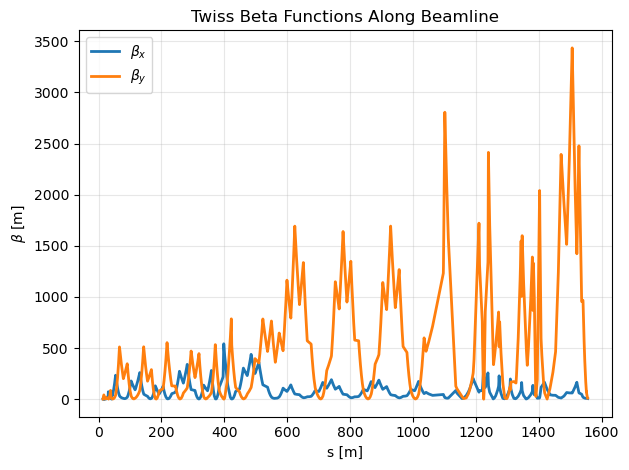

In [85]:
# --- Beta functions ---
plt.plot(
    bmad_output['ele.s'],
    bmad_output['ele.a.beta'],
    label=r'$\beta_x$',
    linewidth=2
)

plt.plot(
    bmad_output['ele.s'],
    bmad_output['ele.b.beta'],
    label=r'$\beta_y$',
    linewidth=2
)

# --- Labels and styling ---
plt.xlabel("s [m]")
plt.ylabel(r"$\beta$ [m]")
plt.title("Twiss Beta Functions Along Beamline")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

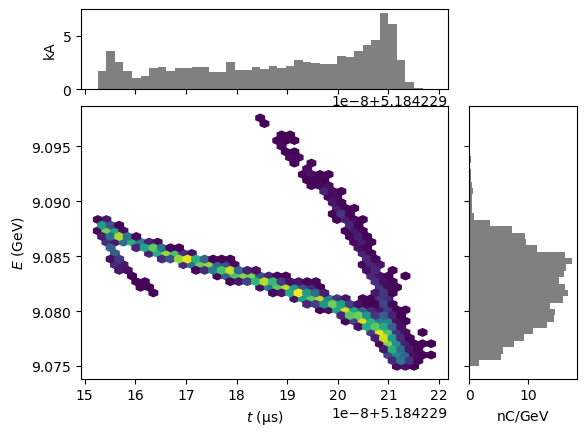

In [86]:
P1 = ParticleGroup(data=tao.bunch_data(TRACK_END))


mask = P1.status == 1

P_alive=P1[mask]

P_alive.plot('t', 'energy')

#### Save particles for Genesis

In [87]:
## Save the output 
folder_path='./store_particles/'
PFILE02 = folder_path + '/Tao_output.h5'
P_alive.write(PFILE02)

# Genesis

In [88]:
PFILE0 = folder_path + 'Tao_output.h5'
P1 = ParticleGroup(PFILE0)
NSAMPLE = len(P1)
P1 = P1.resample(NSAMPLE)

In [89]:

### For some purposes we may want to match the beam 

# Change to s-coordinates (different times t, constant z)
twiss_match = False
alpha_x0 = -0.7393217413918415 
beta_x0 = 7.910909406464387
alpha_y0 = 1.3870723536888105 
beta_y0 = 16.8811786213468987


P1.drift_to_z() # drift to P['mean_z']

#t_ref=0
# Zero out the mean time
#P1.t += t_ref -P1['mean_t']

if twiss_match:
    P1.twiss_match(beta =  beta_x0  , alpha =alpha_x0, plane = 'x', inplace = True)
    P1.twiss_match(beta =  beta_y0  , alpha =alpha_y0, plane = 'y', inplace = True)

In [90]:
from genesis.version4 import Genesis4
from genesis import tools
from genesis.version4 import Genesis4, Write
import genesis.version4 as g4

run_file_location="/sdf/home/j/jmorgan/lclsrepo_dontsharethese/lcls-lattice/genesis/version4/cu_hxr/"
run_file="cu_hxr.in"
Lattice_file="hxr.lat"
workdir="/sdf/scratch/users/j/jmorgan"

G = Genesis4(run_file_location + run_file, lattice= run_file_location + Lattice_file, workdir=workdir, verbose = True)
G.initial_particles = P1
G.input.main.track.zstop=210

G.input.main.namelists.append(Write(beam="end"))  ## write the beam at the end
#G.input.main.namelists.append(Write(field="end"))  ### Write the feild at the end

Removing existing Beam
Updating time namelist slen: 0.000020 (was 0.000015) to span all particles


## Load the undualtor Ks 

#### note we are not currently applying the individual undulator taper - this is still to do. 

In [92]:

pv_file = Path("pvdata_undulator.json")

if pv_file.exists():
    print("Loading undulator PV data from file...")
    with open(pv_file, "r") as f:
        k_vals_list = json.load(f)
    print("Undulator PV data loaded.")

else:
    print("Undulator PV file not found. Pulling from archiver...")

    # Undulator PV numbers
    undulator_pvnums = list(range(1450, 4751, 100))

    # remove the missing ones
    undulator_pvnums.remove(2150)
    undulator_pvnums.remove(2850)

    # build PV list
    pvlist = [f"USEG:UNDH:{n}:KAct" for n in undulator_pvnums]

    # retry logic
    max_retries = 5
    for attempt in range(max_retries):
        try:
            k_vals_list = lcls_archiver_restore(pvlist, time_data)
            print("Undulator PV pull successful.")
            break
        except Exception as e:
            print(f"Attempt {attempt+1} failed: {e}")
            if attempt < max_retries - 1:
                print("Retrying in 2 seconds...")
                time.sleep(2)
            else:
                raise

    # save after successful pull
    with open(pv_file, "w") as f:
        json.dump(k_vals_list, f)

    print("Undulator PV data saved.")

Loading undulator PV data from file...
Undulator PV data loaded.


In [93]:
def get_K_from_pv(k_vals_list):
    """
    Convert PV dictionary into ordered list of K values
    """

    items = []

    for pv, val in k_vals_list.items():
        num = int(pv.split(":")[2])
        items.append((num, val))

    items.sort()

    Klist = [val for _, val in items]

    return Klist

def write_undulator_from_K(usegname_list, Klist, nwig, uperiod):
    """
    Write undulators using measured K values (one K per segment)
    """

    lines = []

    for usegname, K in zip(usegname_list, Klist):
        lines.extend(write_constant_sec(usegname, K, nwig, uperiod))

    return lines

def apply_machine_K(self, k_vals_list, nwig, uperiod):
    """
    Apply undulator K values from machine data (KAct)
    """

    output_lines = []

    lattice = parse_genesis4_lattice_file(self.input.lattice.filename)

    # keep all non-undulator elements
    for key in lattice:
        if key not in ['Undulator', 'Line']:
            output_lines.extend(lattice[key])

    # undulator names
    usegname_list = [und.split(':')[0] for und in lattice['Undulator']]

    # get ordered K list
    Klist = get_K_from_pv(k_vals_list)

    # write undulators
    lines = write_undulator_from_K(usegname_list, Klist, nwig, uperiod)

    output_lines.extend(lines)
    output_lines.extend(lattice['Line'])

    self.input.lattice = g4.Lattice.from_contents(''.join(output_lines))

def parse_genesis4_lattice_file(filename, keys = ['Undulator', 'Quadrupole', 'Corrector', 'Phaseshifter', ' Drift', 'Chicane', 'Marker', 'Line']):
    """
    Parse genesis4 lattice file to an dictionary
    """


    with open(filename) as f:
        lines = f.readlines()
    output = {}
    for key in keys:
        output[key] = []

    ind = 0
    while ind  < len(lines):
        line = lines[ind]
        for key in keys:
            if key.upper() in line.upper() and '#' not in line:
                ele_str = line + ' '
                while '}' not in line:
                    ind += 1
                    line = lines[ind]
                    ele_str += line + ' '

                output[key].append(ele_str)
        ind += 1
    return output    

def write_constant_sec(usegname, K, nwig, uperiod):
    line = usegname + ': Undulator = {lambdau=' + str(uperiod) + ', nwig=' + str(nwig) + ', aw=' + str(K) + '};\n'
    return [line]


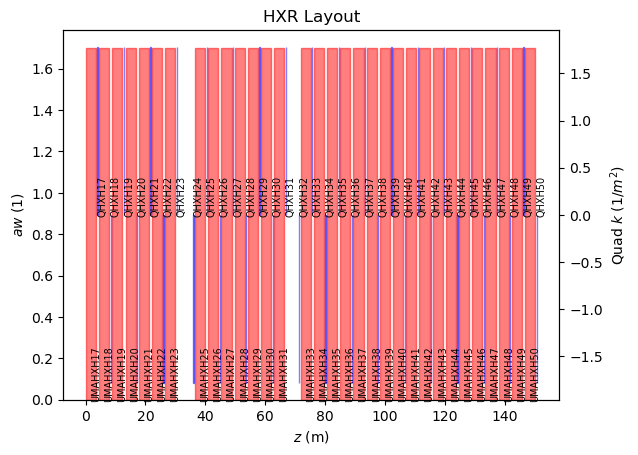

In [94]:
### Before we change K
G.input.lattice.plot("HXR")

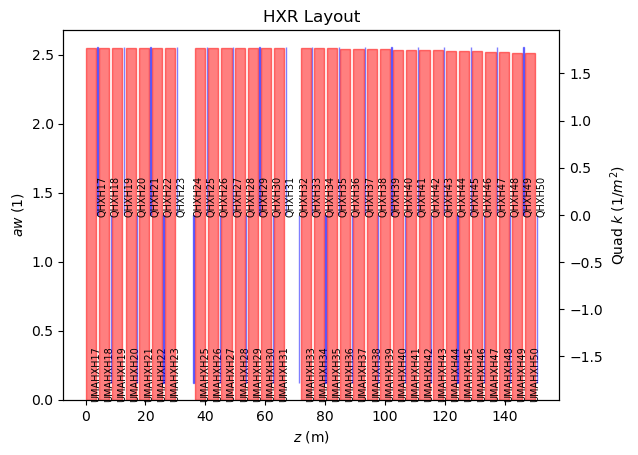

In [95]:
K0 = next(iter(k_vals_list.values()))

k_vals_flat = {k: K0 for k in k_vals_list}

apply_machine_K(
    G,
    k_vals_list,
    nwig=130,
    uperiod=0.026
)

## Look at lattice now we have added the taper

G.input.lattice.plot("HXR")

In [97]:
### update some genesis varibles. 


lu=0.026
gamma=np.mean(P1.gamma)
K=next(iter(k_vals_list.values())) #k_vals[0]
lr=lu/2/gamma**2*(1+K**2)


print(lr)

G.input.main.setup.lambda0=lr  ## make sure genesis is modeling the correct wavelength

3.0878186633166016e-10


In [100]:
nproc=30
G.nproc = nproc


G.mpi_run='salloc --partition milano --account ad:default --mem-per-cpu=4g -n {nproc} mpirun -n {nproc} {command_mpi}'


output=G.run()

Running Genesis4 in /sdf/scratch/users/j/jmorgan/tmp_s2p600f
salloc --partition milano --account ad:default --mem-per-cpu=4g -n 30 mpirun -n 30 /sdf/home/j/jmorgan/conda/envs/lume/bin/genesis4 -l hxr.lat genesis4.in


salloc: Pending job allocation 25618564
salloc: job 25618564 queued and waiting for resources
salloc: job 25618564 has been allocated resources
salloc: Granted job allocation 25618564
salloc: Waiting for resource configuration
salloc: Nodes sdfmilan[102-105] are ready for job


---------------------------------------------
GENESIS - Version 4.6.11 has started...
Compile info: Compiled by conda at 2025-12-03 17:39:36 [UTC] from Git Commit ID: b0f5539b491835b483ec1b6fa143ea4209374edc
Starting Time: Tue Apr 21 12:46:17 2026

MPI-Comm Size: 30 nodes

Opened input file genesis4.in
Parsing lattice file hxr.lat ...
Setting up time window of 20.3796 microns with 330 sample points...
Importing distribution file... 
Charge of external distribution: 1.57751e-10
Particles in external distribution: 6285
*** Non-matching PArticle Transfar: Rank: 19 Deleted: 198 Forward: 61 Backward: 144
*** Non-matching PArticle Transfar: Rank: 18 Deleted: 203 Forward: 68 Backward: 137
Analysing external distribution... 
Analysis of the imported distribution
   Total Bunch Length  (microns): 19.7291
   Length for Matching (microns): 19.7291
   Energy                  (MeV): 9082.19
   Norm. Emittance in x (micron): 2.37851
   Norm. Emittance in y (micron): 2.08186
   Beta Function in x    

salloc: Relinquishing job allocation 25618564


<!-- lume-genesis detected Jupyter and will use HTML for rendering. -->

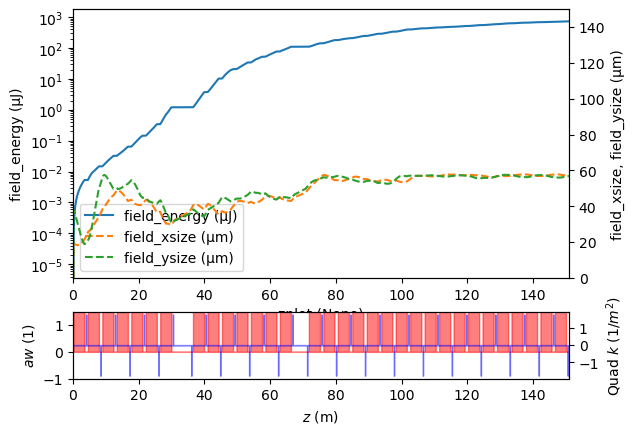

In [101]:
G.plot('field_energy', yscale='log', y2 = ['field_xsize', 'field_ysize'], ylim2=(0e-6, 150e-6))

In [104]:
G.output.field.energy[-1]/1e-3

np.float64(0.7323699515069548)

In [105]:
output.load_particles()


['end']

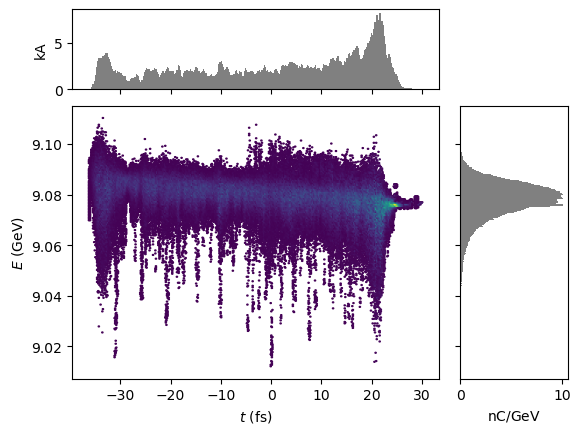

In [106]:
PG = G.output.particles['end']
PG.drift_to_z()
PG.plot('t', 'energy')
